In [1]:
import sys

print(sys.executable)

e:\Phd\Latest Paper\Resume - Thirumurugan\Interview\GenAIinterview\New folder\Final file study\LinkedIn Post\Final one - thiru decideed\LLM Inferecne Engineering\.venv\Scripts\python.exe


# Day 01 Series — LLM Inference Mechanics
**LLM Inference Engineering · 26-day series**

**Goal:** see exactly what happens between "text in" and "text out" when a language model answers a prompt.
No optimizations today. This notebook builds the *naive baseline* that every later day tries to beat.

**Model:** GPT-2 small (124M parameters). It runs on a laptop CPU and has the same structure as much bigger models.
**Time:** about 25 minutes.

## 1. Training vs inference

| | Training | Inference |
|---|---|---|
| What happens | Weights are *adjusted* to predict the next token better | Weights are *frozen* and only read |
| Cost shape | Huge, one-off | Small per request, but paid on every request, forever |
| Optimized for | Learning quality | Latency, throughput, cost |

Every request, no matter the model size, goes through the same pipeline:

```
text  ->  [1 Tokenize]  ->  [2 Forward pass]  ->  [3 Decode]  ->  one new token
                 ^                                                    |
                 +-------------- append and repeat -------------------+
```

In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("PyTorch location:", torch.__file__)
print("Distributed available:", torch.distributed.is_available())

PyTorch version: 2.14.1+cpu
PyTorch location: e:\Phd\Latest Paper\Resume - Thirumurugan\Interview\GenAIinterview\New folder\Final file study\LinkedIn Post\Final one - thiru decideed\LLM Inferecne Engineering\.venv\Lib\site-packages\torch\__init__.py
Distributed available: True


In [16]:
import time
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM

torch.manual_seed(42)

MODEL_NAME = "gpt2"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
model.eval()   # inference mode: switches off training-only behaviour such as dropout

n_params = sum(p.numel() for p in model.parameters())
print(f"model          : {MODEL_NAME}")
print(f"parameters     : {n_params:,}")
print(f"vocabulary     : {tokenizer.vocab_size:,} tokens")
print(f"max context    : {model.config.n_positions} tokens")

Loading weights: 100%|██████████| 148/148 [00:01<00:00, 89.39it/s]


model          : gpt2
parameters     : 124,439,808
vocabulary     : 50,257 tokens
max context    : 1024 tokens


## 2. Stage 1 — Tokenization: text to integers

The model never sees characters. A tokenizer cuts text into **tokens** (whole words, word pieces, or single characters) and maps each one to an integer ID.
Token IDs are the only thing the model can read, and the **token count** is what you are billed for and what drives latency.

In [17]:
prompt = "Inference engineering is the art of making models"

token_ids = tokenizer.encode(prompt)
pieces = [tokenizer.decode([t]) for t in token_ids]

print(f"text        : {prompt!r}")
print(f"token count : {len(token_ids)}\n")
for tid, piece in zip(token_ids, pieces):
    print(f"  {tid:>6d}  ->  {piece!r}")

# decoding the IDs gives the original text back
assert tokenizer.decode(token_ids) == prompt

text        : 'Inference engineering is the art of making models'
token count : 9

     818  ->  'In'
    4288  ->  'ference'
    8705  ->  ' engineering'
     318  ->  ' is'
     262  ->  ' the'
    1242  ->  ' art'
     286  ->  ' of'
    1642  ->  ' making'
    4981  ->  ' models'


In [18]:
# Common words are one token, rare words are split into pieces.
samples = ["the", "inference", "Kubernetes", "autoscaler", "NVIDIA", "192.168.1.1", "def forward(self, x):"]
print(f"{'text':<26s}{'chars':>6s}{'tokens':>8s}   pieces")
for s in samples:
    ids = tokenizer.encode(s)
    print(f"{s!r:<26s}{len(s):>6d}{len(ids):>8d}   {[tokenizer.decode([i]) for i in ids]}")

text                       chars  tokens   pieces
'the'                          3       1   ['the']
'inference'                    9       2   ['in', 'ference']
'Kubernetes'                  10       4   ['K', 'uber', 'net', 'es']
'autoscaler'                  10       4   ['aut', 'os', 'cal', 'er']
'NVIDIA'                       6       1   ['NVIDIA']
'192.168.1.1'                 11       7   ['192', '.', '168', '.', '1', '.', '1']
'def forward(self, x):'       21       7   ['def', ' forward', '(', 'self', ',', ' x', '):']


## 3. Stage 2 — The forward pass: integers to scores

The forward pass feeds the token IDs through the network. The output is a tensor of **logits**: one raw score for *every* vocabulary entry, at *every* input position.

Shape: `[batch, sequence_length, vocab_size]`

In [19]:
inputs = tokenizer(prompt, return_tensors="pt")

with torch.no_grad():                 # inference: no gradient bookkeeping needed
    out = model(**inputs)

logits = out.logits
print("input_ids shape :", tuple(inputs["input_ids"].shape))
print("logits shape    :", tuple(logits.shape), " = [batch, seq_len, vocab]")
print(f"scores per position: {logits.shape[-1]:,}, one per vocabulary entry")

input_ids shape : (1, 9)
logits shape    : (1, 9, 50257)  = [batch, seq_len, vocab]
scores per position: 50,257, one per vocabulary entry


In [20]:
# The model predicts the next token after EVERY prefix, in a single pass.
# For generation we only keep the last position, but the others are computed too.
ids = inputs["input_ids"][0]
best = logits[0].argmax(dim=-1)

print("What the model predicts after each prefix:\n")
for pos in range(len(ids)):
    prefix = tokenizer.decode(ids[: pos + 1].tolist())
    guess = tokenizer.decode([best[pos].item()])
    print(f"  after {prefix!r:<52s} -> {guess!r}")

What the model predicts after each prefix:

  after 'In'                                                 -> ' the'
  after 'Inference'                                          -> ' of'
  after 'Inference engineering'                              -> ' is'
  after 'Inference engineering is'                           -> ' a'
  after 'Inference engineering is the'                       -> ' process'
  after 'Inference engineering is the art'                   -> ' of'
  after 'Inference engineering is the art of'                -> ' making'
  after 'Inference engineering is the art of making'         -> ' things'
  after 'Inference engineering is the art of making models'  -> ' that'


In [21]:
# Scores -> probabilities with softmax, looking at the LAST position only.
next_logits = logits[0, -1, :]
probs = F.softmax(next_logits, dim=-1)

top_p_vals, top_ids = torch.topk(probs, k=10)
print(f"Prompt: {prompt!r}\nTop 10 candidates for the next token:\n")
for p, t in zip(top_p_vals, top_ids):
    print(f"  {p.item():7.2%}   {tokenizer.decode([t.item()])!r}")

print(f"\nprobabilities sum to {probs.sum().item():.4f}")

Prompt: 'Inference engineering is the art of making models'
Top 10 candidates for the next token:

   25.30%   ' that'
   14.00%   ' of'
    6.10%   ' and'
    5.69%   ' out'
    4.04%   ','
    3.29%   ' for'
    2.69%   ' with'
    2.25%   ' in'
    2.19%   ' from'
    1.80%   '.'

probabilities sum to 1.0000


## 4. Stage 3 — Decoding: scores to one token

Now something has to *choose*. That choice is **decoding** (sampling).

| Strategy | Rule |
|---|---|
| **Greedy** | always take the highest-probability token (deterministic) |
| **Temperature** | divide logits by *T* before softmax: low T sharpens, high T flattens |
| **Top-k** | only sample among the *k* most likely tokens |
| **Top-p (nucleus)** | only sample among the smallest set of tokens whose probabilities add up to *p* |

In [22]:
def sample_next(logits, temperature=1.0, top_k=0, top_p=1.0, generator=None):
    # Pick one token ID from a 1-D logits vector. temperature=0 means greedy.
    if temperature == 0:
        return int(torch.argmax(logits))
    logits = logits / temperature
    if top_k > 0:
        kth_best = torch.topk(logits, top_k).values[-1]
        logits = logits.masked_fill(logits < kth_best, float("-inf"))
    probs = F.softmax(logits, dim=-1)
    if top_p < 1.0:
        sorted_probs, sorted_idx = torch.sort(probs, descending=True)
        mass_before = torch.cumsum(sorted_probs, dim=-1) - sorted_probs
        sorted_probs = sorted_probs.masked_fill(mass_before >= top_p, 0.0)
        probs = torch.zeros_like(probs).scatter(0, sorted_idx, sorted_probs)
        probs = probs / probs.sum()
    return int(torch.multinomial(probs, 1, generator=generator))

print("greedy ->", repr(tokenizer.decode([sample_next(next_logits, temperature=0)])))

greedy -> ' that'


In [23]:
# How temperature reshapes the distribution (entropy = how "undecided" the model is)
print(f"{'temp':>5s}  {'top-1 prob':>10s}  {'entropy (bits)':>14s}   top-3")
for T in [0.2, 0.7, 1.0, 1.5, 2.5]:
    p = F.softmax(next_logits / T, dim=-1)
    entropy = -(p * torch.log2(p.clamp_min(1e-12))).sum().item()
    vals, idx = torch.topk(p, 3)
    top3 = ", ".join(f"{tokenizer.decode([i.item()])!r} {v:.0%}" for v, i in zip(vals, idx))
    print(f"{T:>5.1f}  {vals[0].item():>10.1%}  {entropy:>14.2f}   {top3}")

 temp  top-1 prob  entropy (bits)   top-3
  0.2       94.9%            0.30   ' that' 95%, ' of' 5%, ' and' 0%
  0.7       47.8%            2.88   ' that' 48%, ' of' 21%, ' and' 6%
  1.0       25.3%            5.57   ' that' 25%, ' of' 14%, ' and' 6%
  1.5        6.0%           10.54   ' that' 6%, ' of' 4%, ' and' 2%
  2.5        0.5%           13.97   ' that' 1%, ' of' 0%, ' and' 0%


In [24]:
# Same logits, 8 draws each: greedy never changes, sampling does.
settings = {
    "greedy":              dict(temperature=0),
    "T=1.0":               dict(temperature=1.0),
    "T=1.0, top_k=5":      dict(temperature=1.0, top_k=5),
    "T=1.0, top_p=0.9":    dict(temperature=1.0, top_p=0.9),
    "T=0.5":               dict(temperature=0.5),
}
for name, kw in settings.items():
    g = torch.Generator().manual_seed(7)
    draws = [tokenizer.decode([sample_next(next_logits, generator=g, **kw)]) for _ in range(8)]
    print(f"{name:<18s} {draws}")

greedy             [' that', ' that', ' that', ' that', ' that', ' that', ' that', ' that']
T=1.0              [' that', ' of', ' that', ' out', ' of', ',', ' that', ' of']
T=1.0, top_k=5     [' that', ' of', ' that', ' out', ' of', ',', ' that', ' of']
T=1.0, top_p=0.9   [' that', ' of', ' that', ' out', ' of', ',', ' that', ' of']
T=0.5              [' that', ' of', ' that', ' that', ' of', ',', ' that', ' of']


## 5. The autoregressive loop

Put the three stages in a loop, feed each new token back in, and you have text generation.

```
ids = tokenize(prompt)
repeat N times:
    logits = model(ids)[-1]        # forward pass over the WHOLE sequence
    next   = decode(logits)        # pick one token
    ids    = ids + [next]          # append
```
Below is the loop written by hand. It records the time of each step.

In [11]:
def generate_naive(prompt, max_new_tokens=20, temperature=0, top_k=0, top_p=1.0, seed=0):
    g = torch.Generator().manual_seed(seed)
    ids = tokenizer.encode(prompt, return_tensors="pt")
    step_ms, seq_lens = [], []
    for _ in range(max_new_tokens):
        t0 = time.perf_counter()
        with torch.no_grad():
            step_logits = model(ids).logits[0, -1]          # re-reads the ENTIRE sequence
        nxt = sample_next(step_logits, temperature, top_k, top_p, g)
        seq_lens.append(ids.shape[1])
        ids = torch.cat([ids, torch.tensor([[nxt]])], dim=1)
        step_ms.append((time.perf_counter() - t0) * 1000)
    return ids[0], step_ms, seq_lens

prompt2 = "The server crashed because"
out_ids, step_ms, seq_lens = generate_naive(prompt2, max_new_tokens=15)

print(f"prompt: {prompt2!r}\n")
print(f"{'step':>4s} {'tokens fed in':>14s} {'ms':>8s}   new token")
start = len(out_ids) - len(step_ms)
for i, (ms, n) in enumerate(zip(step_ms, seq_lens)):
    print(f"{i+1:>4d} {n:>14d} {ms:>8.1f}   {tokenizer.decode([out_ids[start+i].item()])!r}")
print("\nfull text:", tokenizer.decode(out_ids.tolist()))

prompt: 'The server crashed because'

step  tokens fed in       ms   new token
   1              4    444.3   ' of'
   2              5    450.6   ' a'
   3              6    176.7   ' bug'
   4              7    190.3   ' in'
   5              8    222.5   ' the'
   6              9    158.5   ' server'
   7             10    425.9   "'s"
   8             11   1327.7   ' configuration'
   9             12    253.9   ' file'
  10             13    163.9   '.'
  11             14    172.4   '\n'
  12             15    546.7   '\n'
  13             16    249.2   'The'
  14             17    352.3   ' server'
  15             18    533.7   ' crashed'

full text: The server crashed because of a bug in the server's configuration file.

The server crashed


## 6. What does it cost? Two numbers to know

| Metric | Meaning | In our loop |
|---|---|---|
| **TTFT** (time to first token) | wait before anything appears; the *prefill* of the whole prompt | step 1 |
| **TPOT** (time per output token) | the pace of streaming after that | average of steps 2..N |

Throughput in tokens per second is `1000 / TPOT_ms`. Let's measure a longer run and see how step time behaves.

In [12]:
long_prompt = "Deploying a containerized application to production requires careful planning, because"
with torch.no_grad():
    model(tokenizer.encode(long_prompt, return_tensors="pt"))   # warm-up so timing is fair

NUM_TOKENS = 120
_, step_ms, seq_lens = generate_naive(long_prompt, max_new_tokens=NUM_TOKENS)

ttft = step_ms[0]
tpot = float(np.mean(step_ms[1:]))
slope, intercept = np.polyfit(seq_lens, step_ms, 1)

print(f"TTFT                : {ttft:7.1f} ms")
print(f"TPOT (avg)          : {tpot:7.1f} ms   ->  {1000/tpot:5.1f} tokens/s")
print(f"first vs last step  : {step_ms[0]:.1f} ms -> {step_ms[-1]:.1f} ms")
print(f"step time grows by  : {slope:.3f} ms for every extra token in the sequence")

TTFT                :   159.3 ms
TPOT (avg)          :   467.1 ms   ->    2.1 tokens/s
first vs last step  : 159.3 ms -> 1063.9 ms
step time grows by  : 3.158 ms for every extra token in the sequence


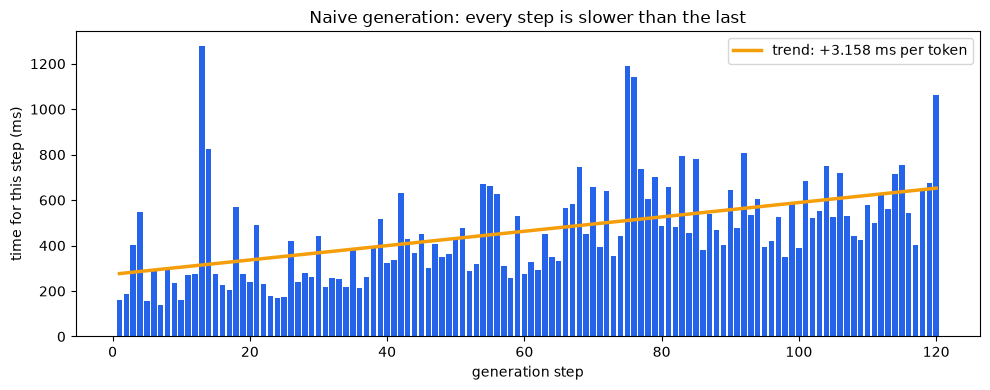

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(1, NUM_TOKENS + 1), step_ms, color="#2563eb")
ax.plot(range(1, NUM_TOKENS + 1), np.polyval([slope, intercept], seq_lens),
        color="#f59e0b", linewidth=2.5, label=f"trend: +{slope:.3f} ms per token")
ax.set_xlabel("generation step")
ax.set_ylabel("time for this step (ms)")
ax.set_title("Naive generation: every step is slower than the last")
ax.legend()
plt.tight_layout()
plt.show()